### import library

In [1]:
import os
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib

DATA = Path("data")
H5_PATH = DATA / "2017_2019_images_pv_processed.hdf5"
CSV_PATH = DATA / "metadata.csv"

### Data preprocessing

#### convert raw data to CSV

In [2]:
dfs = []
with h5py.File(H5_PATH, "r") as f:
    for split in ["trainval", "test"]:
        times = np.load(DATA / f"times_{split}.npy", allow_pickle=True)
        pv = f[split]["pv_log"][:]
        assert len(times) == len(pv) == f[split]["images_log"].shape[0]
        dfs.append(pd.DataFrame({
            "split": split,
            "img_idx": np.arange(len(pv)),
            "time": pd.to_datetime(times),
            "pv_kw": pv,
        }))

meta = pd.concat(dfs, ignore_index=True)
meta.to_csv(CSV_PATH, index=False)
print(f"Saved at {CSV_PATH}, number of lines: {len(meta)}")
print(meta.groupby("split").size())

Saved at data\metadata.csv, number of lines: 363375
split
test         14003
trainval    349372
dtype: int64


#### load data from CSV

In [3]:
meta = pd.read_csv(CSV_PATH, parse_dates=["time"])
f = h5py.File(H5_PATH, "r")

def get_image(row):
    # take the image from meta data and convert BGR to RGB
    return f[row["split"]]["images_log"][row["img_idx"]][..., ::-1]

print(meta.dtypes)
print(meta.head())

split                 str
img_idx             int64
time       datetime64[us]
pv_kw             float64
dtype: object
      split  img_idx                time     pv_kw
0  trainval        0 2017-03-09 06:47:00  0.055691
1  trainval        1 2017-03-09 06:48:00  0.088763
2  trainval        2 2017-03-09 06:49:00  0.109171
3  trainval        3 2017-03-09 06:50:00  0.123206
4  trainval        4 2017-03-09 06:51:00  0.159748


#### overview of the data

Before cleaning, we inspect the raw data to decide what preprocessing is needed.

| Check | Result | Action |
|---|---|---|
| Time range | trainval: 2017-03-09 to 2019-10-26 (497 days, 349,372 rows); test: 20 days (14,003 rows) | — |
| Ordering | trainval is sorted; **test is not sorted by time** | Sort by time |
| Duplicated timestamps | None | — |
| PV range | 0 – 29.6 kW; no negative values, none above the 30.1 kW capacity | No outliners |
| Gap between consecutive rows (same day) | 360086 samples are 1 min; 2534 are under 1 min; 238 are beyong 1min | Remove duplicates after alignment; skip gaps when building samples |
| Timestamp seconds | Only 134931 samples are on the whole minute; the rest are offset by 10–50 s | Align to the minute |
| Days per month | Several months missing (2017-04, 2018-04, 2018-12, 2019-03, 2019-04); winter (Nov–Feb) has only ~11% of days | Note as a limitation; check season balance when splitting |
| Daylight saving | Median daily PV peak is ~13.1–13.6 h in May–Oct vs ~12.4–12.9 h in Dec–Feb (≈1 h shift) | Timestamps follow daylight saving; use timezone America/Los_Angeles (not fixed PST as the README states) |

**Why this matters:** each training sample needs the PV of 15 consecutive minutes and images at fixed offsets (t, t−5, t−10 min). This requires a sorted, gap-aware timeline aligned to whole minutes.

Time range and day range
                       start                 end  n_days  n_rows
split                                                           
test     2017-06-24 06:38:40 2019-10-19 18:15:30      20   14003
trainval 2017-03-09 06:47:00 2019-10-26 17:59:20     497  349372
**************************************************
test sorted: False | duplicated timestamps: 0
trainval sorted: True | duplicated timestamps: 0
**************************************************
count    363375.000000
mean         13.250940
std           7.919619
min           0.000020
25%           5.732333
50%          14.491657
75%          20.558999
max          29.585370
Name: pv_kw, dtype: float64
negative: 0 | > 30.1 kW: 0
**************************************************
Time gap between example
time
1.000000    360086
0.666667       524
0.833333       519
0.500000       510
0.333333       508
0.166667       473
2.000000        48
5.000000        31
1.166667        20
6.000000        14
Name: co

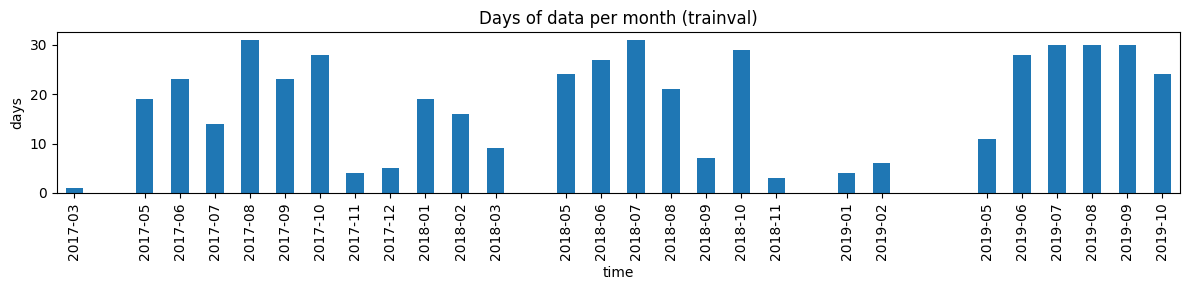

month
1     12.53
2     12.87
3     12.17
5     13.57
6     13.42
7     13.59
8     13.50
9     13.30
10    13.12
11    13.07
12    12.37
Name: peak_hour, dtype: float64


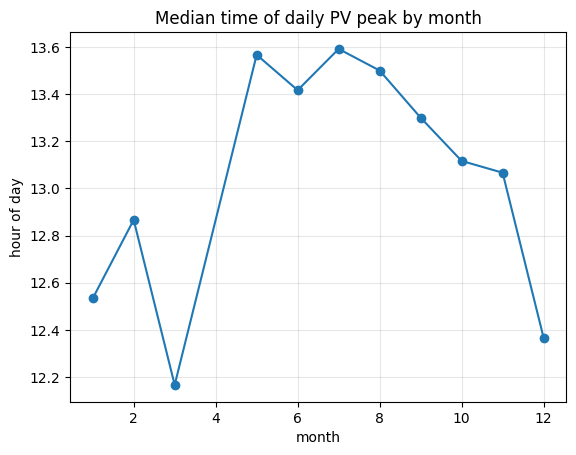

In [4]:
meta["date"] = meta["time"].dt.date

# time range and day range
print("Time range and day range")
print(meta.groupby("split").agg(
    start=("time", "min"), end=("time", "max"),
    n_days=("date", "nunique"), n_rows=("time", "size")))

print("*" * 50)

# check whether sorted or duplicated
for s, g in meta.groupby("split"):
    print(s, "sorted:", g["time"].is_monotonic_increasing,
          "| duplicated timestamps:", g["time"].duplicated().sum())

print("*" * 50)

# check whether outliner for PV
print(meta["pv_kw"].describe())
print("negative:", (meta.pv_kw < 0).sum(), "| > 30.1 kW:", (meta.pv_kw > 30.1).sum())

print("*" * 50)

# check the gap between each example
print("Time gap between example")
gap = meta.sort_values("time").groupby(["split", "date"])["time"].diff().dt.total_seconds() / 60
print(gap.value_counts().head(10))

print("*" * 50)

# seconds of the time stamp
print("Second of time stamp")
print(meta["time"].dt.second.value_counts())

print("*" * 50)

# data for each month
monthly = meta[meta.split == "trainval"].groupby(meta["time"].dt.to_period("M"))["date"].nunique()
monthly.plot(kind="bar", figsize=(12, 3), title="Days of data per month (trainval)")
plt.ylabel("days"); plt.tight_layout(); plt.show()

# Daylight saving check
peak = meta.loc[meta.groupby("date")["pv_kw"].idxmax(), ["date", "time"]]
peak["month"] = pd.to_datetime(peak["date"]).dt.month
peak["peak_hour"] = peak["time"].dt.hour + peak["time"].dt.minute / 60
peak_by_month = peak.groupby("month")["peak_hour"].median()
print(peak_by_month.round(2))

peak_by_month.plot(marker="o", title="Median time of daily PV peak by month")
plt.xlabel("month"); plt.ylabel("hour of day"); plt.grid(alpha=0.3); plt.show()

#### Cleaning

**Sort by time.** Rows are sorted by `split`, then by `time`, so the test set is in chronological order. `img_idx` is kept, so every row still points to its own image.
*Why:* later steps (persistence, rolling windows, weather bins) use "the previous row" or "the previous 15 rows" and would silently be wrong on unsorted data.

**Align to whole minutes and remove duplicates.** Each timestamp is floored to the minute (new column `time_min`). When two rows fall into the same minute, only the first is kept: **1,353 rows removed (0.37%)**.
*Why:* samples look up exact minutes (e.g. t−5, t−10). Timestamps with seconds (10:10:30) cannot be matched to 10:10:00.

**Verification.** After cleaning: all seconds are 0, no duplicated minutes, and all gaps are whole minutes (361282 one-minute steps; 223 real gaps beyond 1 min which are skipped when building samples).
Rows after cleaning: **trainval 348,060, test 13,962**.

In [5]:
# sort the dataset (mainly for testing)
meta = meta.sort_values(["split", "time"]).reset_index(drop=True)

# align time stramp to min, and remove duplicated
meta["time_min"] = meta["time"].dt.floor("min")
dup = meta.duplicated(["split", "time_min"], keep="first")
meta = meta[~dup].reset_index(drop=True)
meta["date"] = meta["time_min"].dt.date

print("seconds after flooring:", meta["time_min"].dt.second.unique())
print("duplicated:", meta.duplicated(["split", "time_min"]).sum())
gap_min = meta.groupby(["split", "date"])["time_min"].diff().dt.total_seconds() / 60
print(gap_min.value_counts().head(10))
print(meta.groupby("split").size())

print("*" * 50)

seconds after flooring: [0]
duplicated: 0
time_min
1.0     361282
2.0         53
5.0         33
6.0         14
4.0          6
15.0         5
3.0          5
7.0          4
67.0         3
17.0         3
Name: count, dtype: int64
split
test         13962
trainval    348060
dtype: int64
**************************************************


#### checking wheter image are usful for PV

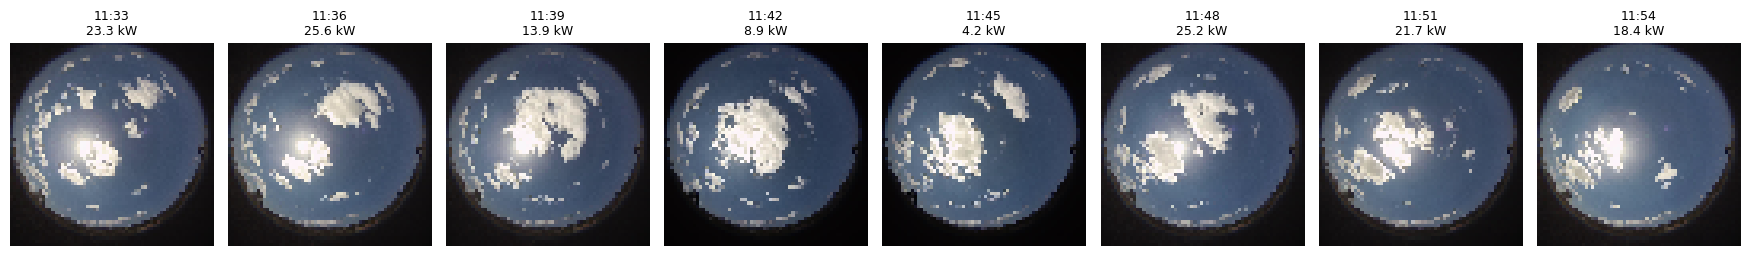

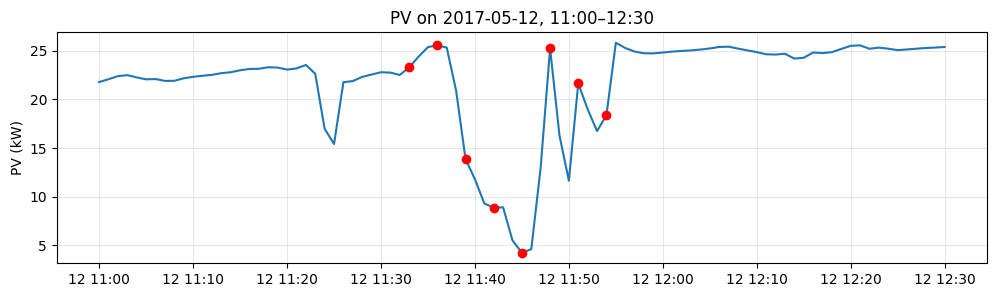

In [6]:
# add timezone (timestamps follow daylight saving, see the overview)
meta["time_local"] = meta["time_min"].dt.tz_localize("America/Los_Angeles")

# a cloud passing the sun on 2017-05-12
day = pd.Timestamp("2017-05-12").date()
d = meta[(meta.split == "trainval") & (meta.date == day)].reset_index(drop=True)

seg = d[(d.time_min >= f"{day} 11:33") & (d.time_min <= f"{day} 11:54")].iloc[::3]

# images every 3 minutes
fig, axes = plt.subplots(1, len(seg), figsize=(2.2 * len(seg), 2.5))
for ax, (_, r) in zip(axes, seg.iterrows()):
    ax.imshow(get_image(r)); ax.axis("off")
    ax.set_title(f"{r.time_min:%H:%M}\n{r.pv_kw:.1f} kW", fontsize=9)
plt.tight_layout(); plt.show()

# PV around the event, with the image times marked
win = d[(d.time_min >= f"{day} 11:00") & (d.time_min <= f"{day} 12:30")]
plt.figure(figsize=(12, 3))
plt.plot(win.time_min, win.pv_kw)
plt.scatter(seg.time_min, seg.pv_kw, color="red", zorder=3)
plt.ylabel("PV (kW)"); plt.title(f"PV on {day}, 11:00–12:30"); plt.grid(alpha=0.3); plt.show()

#### Sun position and clear-sky power

We use pvlib to compute, for every minute, the position of the sun and the power the panel would produce under a clear sky. These are needed later for the clear-sky index, the sun-position features of the model, and for removing sunrise/sunset periods. We also check, day by day, that the measured PV lines up in time with the clear-sky curve, to make sure the timezone is correct for every day.

303 clear days | shift between curves (min): median 2.7, largest 16.8


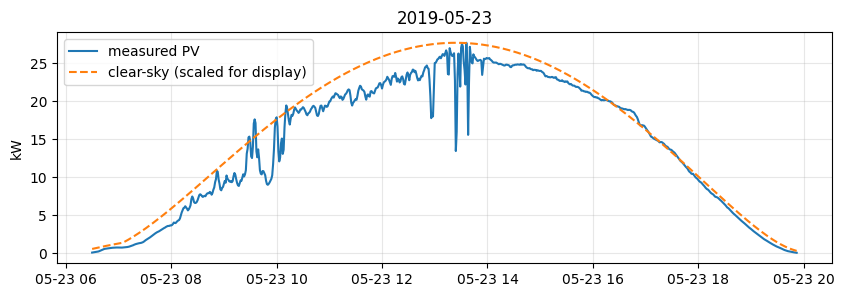

In [7]:
# site and panel parameters (from the dataset description)
LAT, LON, ALT = 37.427, -122.174, 30       # approx. location of Stanford
TILT, AZIMUTH, CAPACITY = 22.5, 195, 30.1  # panel tilt (deg), azimuth (deg), capacity (kW)
site = pvlib.location.Location(LAT, LON, tz="America/Los_Angeles", altitude=ALT)
times = pd.DatetimeIndex(meta["time_local"])

# sun position
solpos = site.get_solarposition(times)
meta["sun_elev"] = solpos["apparent_elevation"].to_numpy()
meta["sun_azim"] = solpos["azimuth"].to_numpy()

# theoretical clear-sky power on the tilted panel (kW, not yet calibrated)
cs = site.get_clearsky(times, solar_position=solpos)
poa = pvlib.irradiance.get_total_irradiance(TILT, AZIMUTH, solpos["apparent_zenith"], solpos["azimuth"],
                                            cs["dni"], cs["ghi"], cs["dhi"])
meta["p_clear_raw"] = CAPACITY * poa["poa_global"].to_numpy() / 1000

# timing check: on clear days, measured PV and clear-sky curve should be centred at the same time
def center_hour(t, w):
    hour = t.dt.hour + t.dt.minute / 60
    return (hour * w).sum() / w.sum()

rows = []
for date, g in meta.groupby("date"):
    if g.time_min.diff().max() > pd.Timedelta("30min"):     # skip days with large gaps
        continue
    corr = g.pv_kw.corr(g.p_clear_raw)                       # close to 1 on clear days
    shift = (center_hour(g.time_local, g.pv_kw) - center_hour(g.time_local, g.p_clear_raw)) * 60
    rows.append((date, corr, shift))
check = pd.DataFrame(rows, columns=["date", "corr", "shift_min"])

clear = check[check["corr"] > 0.98]
print(f"{len(clear)} clear days | shift between curves (min): "
      f"median {clear.shift_min.median():.1f}, largest {clear.shift_min.abs().max():.1f}")

# example
g = meta[meta.date == pd.Timestamp("2019-05-23").date()]
plt.figure(figsize=(10, 3))
plt.plot(g.time_local, g.pv_kw, label="measured PV")
plt.plot(g.time_local, g.p_clear_raw * g.pv_kw.max() / g.p_clear_raw.max(), "--", label="clear-sky (scaled for display)")
plt.ylabel("kW"); plt.title("2019-05-23"); plt.legend(); plt.grid(alpha=0.3); plt.show()

#### remove samples that with sun lowing

In [8]:
# remove low-sun periods (sunrise / sunset)
MIN_ELEV = 10   # degrees
before = meta.groupby("split").size()
meta = meta[meta.sun_elev >= MIN_ELEV].reset_index(drop=True)
after = meta.groupby("split").size()
print(pd.DataFrame({"before": before, "after": after, "removed": before - after}))

          before   after  removed
split                            
test       13962   12742     1220
trainval  348060  319813    28247


#### Remove stuck PV readings

In some periods the PV log repeats exactly the same value (to 10⁻⁶ kW) for several consecutive minutes, for example 12.50737 kW for 38 minutes in a row. A real measurement cannot do this in daylight, because the sun keeps moving and the output always changes a little. These values were probably filled in when no new reading was recorded.

Any run of 2 or more consecutive minutes with the same value is removed completely, including its first row. The same rule is applied to trainval and test. The removed minutes become ordinary gaps, so the later steps automatically skip any sample whose history or target touches them, in the same way as for the other gaps in the data.

stuck runs: 76 | rows: 655 (0.20%) | days: 43
split
test          5
trainval    650
dtype: int64
run length (min) -> number of runs
pv_kw
2     21
3     12
4      2
5      2
6      2
7      2
8      1
9      1
10     1
11     2
12     1
13    13
14     9
18     1
19     1
20     1
22     1
24     1
36     1
38     1
Name: count, dtype: int64
sun elevation of stuck rows:
count    655.0
mean      39.0
std       15.8
min       10.2
25%       25.7
50%       37.8
75%       53.5
max       73.9
Name: sun_elev, dtype: float64


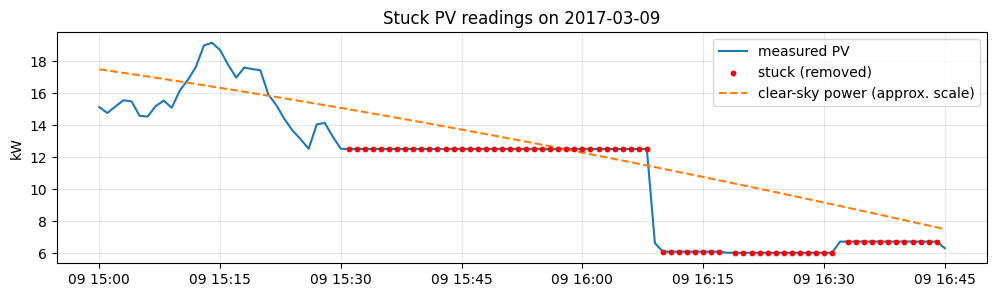

          before   after  removed
split                            
test       12742   12737        5
trainval  319813  319163      650


In [9]:
# remove "stuck" PV readings: the same value repeated over consecutive minutes
same_day = (meta.split == meta.split.shift()) & (meta.date == meta.date.shift())
next_min = meta.time_min.diff() == pd.Timedelta("1min")
repeat = same_day & next_min & ((meta.pv_kw - meta.pv_kw.shift()).abs() < 1e-6)

run_id = (~repeat).cumsum()                                    # rows of one run share an id
run_len = meta.groupby(run_id)["pv_kw"].transform("size")
stuck = run_len >= 2                                           # the whole run, including its first row

print(f"stuck runs: {run_id[stuck].nunique()} | rows: {stuck.sum()} ({stuck.mean():.2%}) | days: {meta.loc[stuck, 'date'].nunique()}")
print(meta[stuck].groupby("split").size())
print("run length (min) -> number of runs")
print(run_len[stuck].groupby(run_id[stuck]).first().value_counts().sort_index())
print("sun elevation of stuck rows:")
print(meta.loc[stuck, "sun_elev"].describe().round(1))

# example: 2017-03-09
day = pd.Timestamp("2017-03-09").date()
w = (meta.date == day) & (meta.time_min >= f"{day} 15:00") & (meta.time_min <= f"{day} 16:45")
g = meta[w]
plt.figure(figsize=(12, 3))
plt.plot(g.time_min, g.pv_kw, label="measured PV")
plt.scatter(g.time_min[stuck[w]], g.pv_kw[stuck[w]], color="red", s=10, zorder=3, label="stuck (removed)")
plt.plot(g.time_min, g.p_clear_raw * 0.82, "--", label="clear-sky power (approx. scale)")
plt.ylabel("kW"); plt.title(f"Stuck PV readings on {day}"); plt.legend(); plt.grid(alpha=0.3); plt.show()

before = meta.groupby("split").size()
meta = meta[~stuck].reset_index(drop=True)
after = meta.groupby("split").size()
print(pd.DataFrame({"before": before, "after": after, "removed": before - after}))

#### Cross-validation folds and test set

The test set is the official 20 days (10 sunny, 10 cloudy) and is used only once at the end. The remaining 497 days are split into **5 folds by whole day**, so nearly identical neighbouring minutes never end up in different folds. The split is **stratified by month**, so each fold has a similar seasonal mix despite the small number of winter days.

Each model is trained 5 times, each time on 4 folds and evaluated on the held-out fold. This gives a more reliable estimate of performance (mean ± std over folds) and an out-of-fold prediction for every day, which is used for conformal calibration instead of a separate calibration set (Angelopoulos & Bates 2021, Sec. 6.2). Early stopping uses a small set of days taken from the training folds, so the held-out fold is never used during training.

The random seed is fixed and the day-to-fold assignment is saved to `split_days.csv`.

In [10]:
# split trainval days into 5 folds (by whole day, stratified by month); test = official 20 days
K = 5
rng = np.random.default_rng(1)

# test days must not appear in trainval
tv_dates = set(meta.loc[meta.split == "trainval", "date"])
te_dates = set(meta.loc[meta.split == "test", "date"])
assert not tv_dates & te_dates, "test days also appear in trainval"

# assign each trainval day to a fold, month by month
days = pd.DataFrame({"date": sorted(tv_dates)})
days["month"] = pd.to_datetime(days["date"]).dt.to_period("M")

fold_of_day = {}
for _, g in days.groupby("month"):
    d = g["date"].to_numpy().copy()
    rng.shuffle(d)
    start = rng.integers(K)              # random start so small months don't all go to fold 0
    for i, x in enumerate(d):
        fold_of_day[x] = (start + i) % K

meta["fold"] = -1                        # -1 = test
is_tv = meta.split == "trainval"
meta.loc[is_tv, "fold"] = meta.loc[is_tv, "date"].map(fold_of_day)

# summary: days and rows per fold
print(meta.groupby("fold").agg(days=("date", "nunique"), rows=("date", "size")))

# season balance: days per fold by month of year
day_table = meta.drop_duplicates(["split", "date"])[["date", "split", "fold"]].sort_values("date")
day_table["month"] = pd.to_datetime(day_table["date"]).dt.month
print(pd.crosstab(day_table.month, day_table.fold))

# save the day → fold list for reproducibility
os.makedirs(DATA / "processed", exist_ok=True)
day_table[["date", "split", "fold"]].to_csv(DATA / "processed" / "split_days.csv", index=False)

      days   rows
fold             
-1      20  12737
 0      99  62989
 1      98  62965
 2     101  63401
 3     101  65790
 4      98  64018
fold   -1   0   1   2   3   4
month                        
1       2   5   5   5   4   4
2       1   5   4   4   5   4
3       1   1   2   3   2   2
5       1  11  10  10  11  12
6       5  14  15  16  17  16
7       1  15  15  14  15  16
8       1  16  16  17  17  16
9       2  13  12  12  11  12
10      6  16  16  17  17  15
11      0   2   2   2   1   0
12      0   1   1   1   1   1


#### coumpute clear sky index k

In [11]:
# compute the clear-sky index k
r = meta.pv_kw / meta.p_clear_raw

# clear and stable minutes on trainval days (never use test):
# ratio barely changes over 15 min, not under a cloud, sun high enough for the model to be reliable
roll_std = r.groupby([meta.split, meta.date]).transform(lambda s: s.rolling(15, center=True).std())
clear_min = (meta.split == "trainval") & (roll_std < 0.01) & (r > 0.6) & (meta.sun_elev >= 20)

SCALE = r[clear_min].median()
print(f"{clear_min.sum()} clear, stable minutes on {meta.loc[clear_min, 'date'].nunique()} trainval days")
print(f"scale factor = {SCALE:.3f}")

meta["p_clear"] = SCALE * meta.p_clear_raw
meta["k"] = meta.pv_kw / meta.p_clear
print(meta.groupby("split")["k"].describe(percentiles=[0.01, 0.5, 0.99]).round(3))

177820 clear, stable minutes on 456 trainval days
scale factor = 0.819
             count   mean    std   min     1%    50%    99%    max
split                                                             
test       12737.0  0.904  0.296  0.09  0.205  0.984  1.475  1.946
trainval  319163.0  0.925  0.242  0.00  0.154  0.981  1.370  2.457


#### label day either: sunny or cloudy or changeing day

In the trainval data, 66% of minutes are clear, 24% variable and 7% overcast (3% have no bin because the previous 15 minutes are incomplete). The five folds have very similar mixes (clear 64–71%, variable 20–25%, overcast 7–8%), so cross-validation results are comparable across folds. Overcast conditions are rare, so results in that bin will be less certain. The official test set is cloudier (52% clear, 33% variable, 12% overcast) because it was chosen as 10 sunny and 10 cloudy days, so test errors may be higher than cross-validation errors.

In [12]:
# weather bins from the last 15 minutes of k (t-14 .. t)
def window_stats(g):
    roll = g.set_index("time_min")["k"].rolling("15min", min_periods=15)   # needs all 15 minutes
    return pd.DataFrame({"k_mean15": roll.mean().to_numpy(),
                         "k_std15": roll.std().to_numpy()}, index=g.index)

stats = meta.groupby(["split", "date"], group_keys=False)[["time_min", "k"]].apply(window_stats)
meta[["k_mean15", "k_std15"]] = stats

CLEAR_MEAN, CLEAR_STD, OVERCAST_MEAN = 0.80, 0.03, 0.50
meta["weather"] = np.select(
    [meta.k_mean15.isna(),                                        # not 15 full minutes yet
     meta.k_mean15 < OVERCAST_MEAN,                               # low: overcast
     (meta.k_mean15 >= CLEAR_MEAN) & (meta.k_std15 < CLEAR_STD)], # high and stable: clear
    ["none", "overcast", "clear"], default="variable")            # everything else: variable

print(pd.crosstab(meta.split, meta.weather, normalize="index").round(3))
print(pd.crosstab(meta.fold, meta.weather, normalize="index").round(3))

weather   clear   none  overcast  variable
split                                     
test      0.521  0.025     0.121     0.334
trainval  0.662  0.030     0.072     0.236
weather  clear   none  overcast  variable
fold                                     
-1       0.521  0.025     0.121     0.334
 0       0.652  0.032     0.073     0.243
 1       0.706  0.028     0.066     0.200
 2       0.660  0.029     0.067     0.243
 3       0.654  0.028     0.079     0.239
 4       0.641  0.031     0.075     0.253


#### Building samples

A sample is a start time t and a horizon h (15, 30 or 60 minutes). Its inputs are the clear-sky index k of the last 15 minutes (t−14 … t), the sky images at t−10, t−5 and t, and the sun position; its target is k at t+h (converted back to kW with the clear-sky power at t+h for evaluation).

A start time is valid only if all 15 previous minutes exist on the same day (checked with assertions), and the target minute t+h exists on the same day with the sun above 10°.

In [13]:
# build samples for each forecast horizon
meta = meta.reset_index(drop=True)             # row number = index; samples below refer to these rows
HORIZONS = [15, 30, 60]                         # minutes ahead
HIST, IMG_OFFSETS = 15, [10, 5, 0]              # 15 minutes of k history; images at t-10, t-5, t

# possible start times t: minutes with 15 complete previous minutes
starts = (meta.loc[meta.weather != "none", ["split", "date", "fold", "weather", "time_min"]]
              .reset_index().rename(columns={"index": "row_t"}))
lookup = (meta[["split", "date", "time_min"]].reset_index()
              .rename(columns={"index": "row_y", "time_min": "time_y"}))

# sanity check: the 15 history rows before each start are consecutive minutes of the same day
first = starts.row_t - (HIST - 1)
assert (meta.time_min.to_numpy()[first] == (starts.time_min - pd.Timedelta(minutes=HIST - 1)).to_numpy()).all()
assert (meta.date.to_numpy()[first] == starts.date.to_numpy()).all()

# for each horizon, keep starts whose target minute t+h exists on the same day
samples = {}
for h in HORIZONS:
    s = starts.assign(time_y=starts.time_min + pd.Timedelta(minutes=h))
    s = s.merge(lookup, on=["split", "date", "time_y"], how="inner")
    samples[h] = s[["row_t", "row_y", "split", "fold", "weather", "time_min", "time_y"]]
    samples[h].to_csv(DATA / "processed" / f"samples_h{h}.csv", index=False)

# save the table the row numbers refer to
meta.to_csv(DATA / "processed" / "meta_processed.csv", index=False)

# summary: samples per fold and weather mix, for each horizon
print(pd.DataFrame({f"{h} min": samples[h].groupby("fold").size() for h in HORIZONS}))
print(pd.DataFrame({f"{h} min": samples[h].weather.value_counts(normalize=True).round(3) for h in HORIZONS}))

      15 min  30 min  60 min
fold                        
-1     12118   11818   11218
 0     59072   57402   54320
 1     59464   57854   54791
 2     59771   58114   54948
 3     62175   60562   57383
 4     60242   58590   55548
          15 min  30 min  60 min
weather                         
clear      0.681   0.681   0.679
variable   0.243   0.244   0.246
overcast   0.076   0.076   0.075
